# Jet Tagging with CNNs
**CNNs and GNNs as classifiers for sparse data events**

**Tasks:** Multiclass classification of jets originating from: *gluon (g), quark (q), W boson, Z boson, top quark*.

Pipeline:
1. Load dataset and visualise features
2. Build jet images (2D histogram of constituent $p_T$ in the $\eta$–$\phi$ plane)
3. Design & train a CNN  
4. Evaluate performance (accuracy, confusion matrix, ROC curves)

In [7]:
# --- Imports ---
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import itertools, os, warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
warnings.filterwarnings('ignore')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 1. Load Dataset
The `.npz` file contains:
- `features`: shape `(20000, 100, 16)` — 20k jets, up to 100 constituents, 16 features each
- `target`: one-hot labels of shape `(20000, 5)` for classes `[g, q, W, Z, t]`

In [8]:
# Load dataset
with np.load('dataset_jetTag.npz') as f:
    target   = f['target']
    features = f['features']

# Convert one-hot labels to integer class indices
label = np.argmax(target, axis=1)
labels_str = ['gluon', 'quark', 'W', 'Z', 'top']

print(f"Features shape : {features.shape}")
print(f"Labels shape   : {label.shape}")
print(f"Class distribution: {dict(zip(labels_str, np.bincount(label)))}") 

Features shape : (20000, 100, 16)
Labels shape   : (20000,)
Class distribution: {'gluon': 4114, 'quark': 3940, 'W': 4039, 'Z': 3950, 'top': 3957}


## 2. Train / Validation / Test Split (80 / 10 / 10)

In [9]:
X_train, X_rem, y_train, y_rem = train_test_split(features, label, train_size=0.8, random_state=42)
X_valid, X_test, y_valid, y_test = train_test_split(X_rem, y_rem, test_size=0.5, random_state=42)
print("Train:", X_train.shape, "| Valid:", X_valid.shape, "| Test:", X_test.shape)

Train: (16000, 100, 16) | Valid: (2000, 100, 16) | Test: (2000, 100, 16)


## 3. Create Jet Images

Each jet is turned into a **100×100 image** by histogramming the constituent transverse momenta ($p_T$) 
into bins of the relative pseudorapidity–azimuth plane $(\eta_{rel}, \phi_{rel})$.  
This is the representation described in the lecture (slide 81): "*classify jets based on the 2D histogram of $p_T$*".

> **Note on sparse data:** As the lecture recommends (slide 82), we use **large convolutional kernels (11×11)** 
> in the first layer to capture features efficiently in these sparse images.

In [10]:
def create_images(features, bins=100):
    """Project each jet constituent pT onto a 100x100 eta-phi grid."""
    jet_imgs = np.empty((features.shape[0], bins, bins), dtype=np.float32)
    for i in range(features.shape[0]):
        eta = features[i, :, 8]   # eta_rel  (feature index 8)
        phi = features[i, :, 11]  # phi_rel  (feature index 11)
        pt  = features[i, :, 5]   # pT       (feature index 5)
        h, _, _ = np.histogram2d(eta, phi, bins=bins,
                                 range=[[-1,1],[-1,1]], weights=pt)
        jet_imgs[i] = h
    return jet_imgs

print("Creating jet images … (this takes ~1–2 min)")
jet_imgs_train = create_images(X_train)
jet_imgs_valid = create_images(X_valid)
jet_imgs_test  = create_images(X_test)
print(f"Train image shape: {jet_imgs_train.shape}")

Creating jet images … (this takes ~1–2 min)
Train image shape: (16000, 100, 100)


### Example jet image

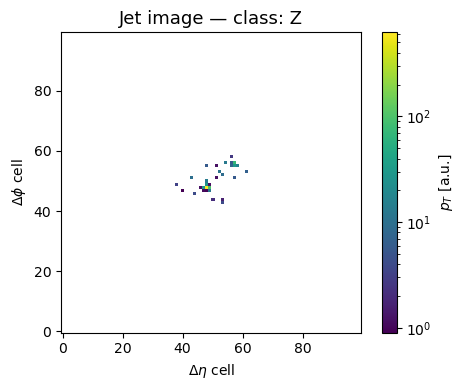

In [11]:
idx = 42
plt.figure(figsize=(5,4))
plt.imshow(jet_imgs_train[idx], origin='lower', norm=LogNorm())
plt.colorbar(label='$p_T$ [a.u.]')
plt.title(f'Jet image — class: {labels_str[y_train[idx]]}', fontsize=13)
plt.xlabel('$\Delta\eta$ cell'); plt.ylabel('$\Delta\phi$ cell')
plt.tight_layout(); plt.show()

### Mean jet image per class
Summing all images in each category reveals the typical energy deposition pattern.

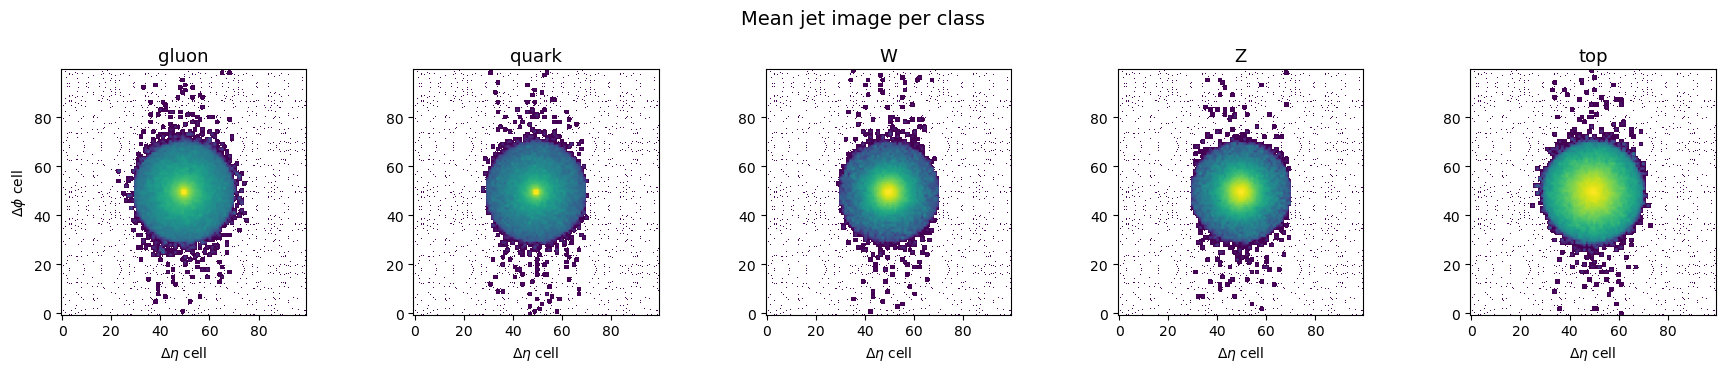

In [12]:
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
for i, label_name in enumerate(labels_str):
    mask = (y_train == i)
    mean_img = jet_imgs_train[mask].mean(axis=0)
    im = axes[i].imshow(mean_img, origin='lower', norm=LogNorm(), cmap='viridis')
    axes[i].set_title(label_name, fontsize=13)
    axes[i].set_xlabel('$\Delta\eta$ cell')
    if i == 0: axes[i].set_ylabel('$\Delta\phi$ cell')
plt.suptitle('Mean jet image per class', fontsize=14, y=1.01)
plt.tight_layout(); plt.show()

## 4. Preprocessing

Before feeding images to the CNN we:
1. **Downsample** from 100×100 → 50×50 using local averaging (reduces memory)
2. **Log-transform** pixel values: $\tilde{p}_T = \log(1 + p_T)$ — compresses the dynamic range
3. **Add channel dimension** (required by `Conv2D`)
4. **One-hot encode** the labels

In [13]:
from skimage.transform import downscale_local_mean

def preprocess(imgs, target_size=50):
    factor = imgs.shape[1] // target_size
    out = np.empty((imgs.shape[0], target_size, target_size), dtype=np.float32)
    for i in range(imgs.shape[0]):
        out[i] = downscale_local_mean(imgs[i], (factor, factor))
    return np.log1p(out)[..., np.newaxis]   # log1p + channel dim

X_train_pp = preprocess(jet_imgs_train)
X_valid_pp = preprocess(jet_imgs_valid)
X_test_pp  = preprocess(jet_imgs_test)

n_classes = 5
Y_train = keras.utils.to_categorical(y_train, n_classes)
Y_valid = keras.utils.to_categorical(y_valid, n_classes)
Y_test  = keras.utils.to_categorical(y_test, n_classes)

print("Preprocessed shape:", X_train_pp.shape)
print("Value range — min:", X_train_pp.min().round(3), " max:", X_train_pp.max().round(3))

Preprocessed shape: (16000, 50, 50, 1)
Value range — min: 0.0  max: 6.013


## 5. CNN Architecture

Following the **lecture guidelines** (slides 75, 82):
- **Large initial kernel (11×11)**: recommended for sparse physics images instead of the standard 3×3
- **Increasing filter count** per block: 16 → 32 → 64  
- **Max Pooling** after each block to reduce spatial dimensions and introduce local invariance  
- **Dropout** in the classifier head to regularise
- **GlobalAveragePooling** instead of Flatten to reduce the parameter count
- **Softmax** output + **CategoricalCrossentropy** loss for 5-class classification

In [14]:
tf.random.set_seed(42)

model = keras.Sequential([
    keras.Input(shape=(50, 50, 1)),

    # Block 1 — large kernel for sparse jet images (lecture slide 82)
    layers.Conv2D(16, (11, 11), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(32, (5, 5), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.GlobalAveragePooling2D(),

    # Classification head
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(n_classes, activation='softmax'),
], name='JetCNN')

model.summary()

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "JetCNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 50, 50, 16)     │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 25, 25, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 25, 25, 32)     │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 37,765 (147.52 KB)

 Trainable params: 37,765 (147.52 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Training

In [15]:
history = model.fit(
    X_train_pp, Y_train,
    validation_data=(X_valid_pp, Y_valid),
    epochs=15,
    batch_size=256,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, verbose=1),
    ],
    verbose=1,
)

Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 318ms/step - accuracy: 0.2569 - loss: 1.5702 - val_accuracy: 0.4805 - val_loss: 1.4333 - learning_rate: 0.0010
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 357ms/step - accuracy: 0.4735 - loss: 1.3032 - val_accuracy: 0.5550 - val_loss: 1.1288 - learning_rate: 0.0010
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 346ms/step - accuracy: 0.5272 - loss: 1.1549 - val_accuracy: 0.5705 - val_loss: 1.0581 - learning_rate: 0.0010
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 21s 328ms/step - accuracy: 0.5519 - loss: 1.0977 - val_accuracy: 0.5780 - val_loss: 1.0187 - learning_rate: 0.0010
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 20s 317ms/step - accuracy: 0.5676 - loss: 1.0656 - val_accuracy: 0.5855 - val_loss: 1.0071 - learning_rate: 0.0010
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 347ms/step - accuracy: 0.5861 - loss: 1.0385 - val_accuracy: 0.6150 - val_loss: 0.9789 - learning_rate: 0.0010
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 23s 369ms/step - accuracy: 0.5973 - loss: 1.

## 7. Performance Assessment
### Training curves

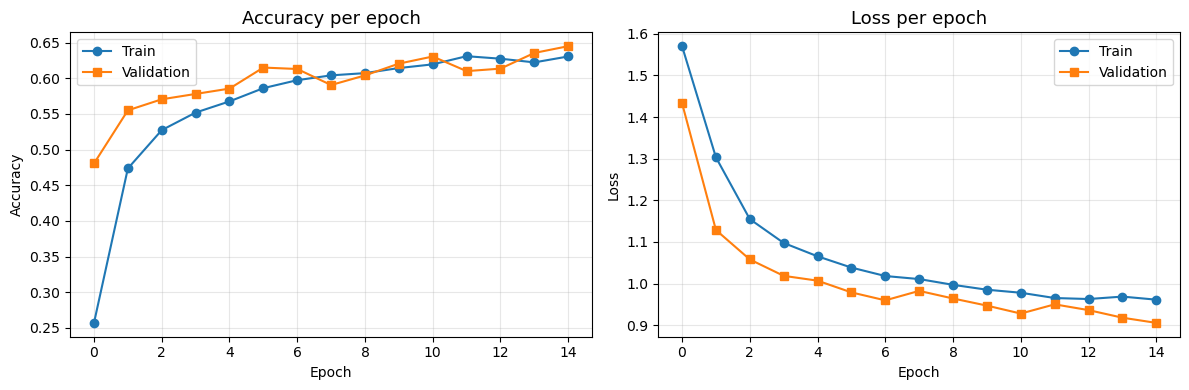

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], 'o-', label='Train')
axes[0].plot(history.history['val_accuracy'], 's-', label='Validation')
axes[0].set_title('Accuracy per epoch', fontsize=13)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history['loss'], 'o-', label='Train')
axes[1].plot(history.history['val_loss'], 's-', label='Validation')
axes[1].set_title('Loss per epoch', fontsize=13)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Confusion Matrix

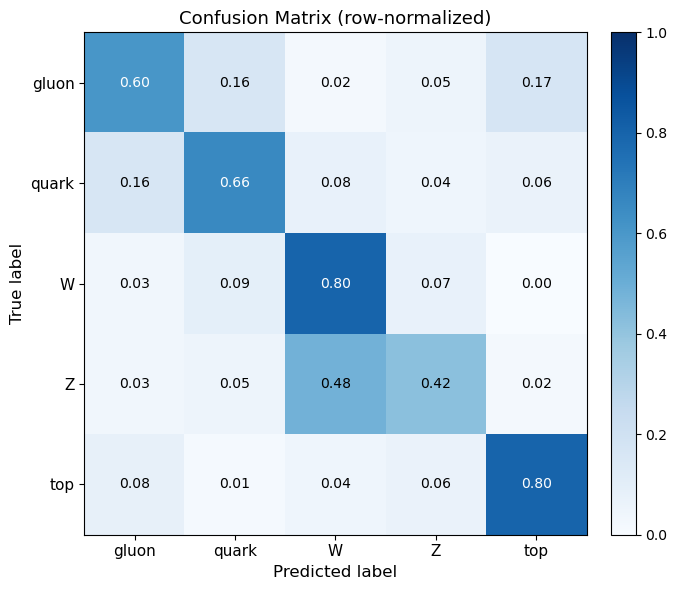

In [17]:
y_pred_prob = model.predict(X_test_pp, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis]

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, interpolation='nearest', cmap='Blues', vmin=0, vmax=1)
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_xticks(range(n_classes)); ax.set_yticks(range(n_classes))
ax.set_xticklabels(labels_str, fontsize=11); ax.set_yticklabels(labels_str, fontsize=11)
for i, j in itertools.product(range(n_classes), range(n_classes)):
    ax.text(j, i, f'{cm_norm[i,j]:.2f}', ha='center', va='center',
            color='white' if cm_norm[i,j] > 0.5 else 'black', fontsize=10)
ax.set_xlabel('Predicted label', fontsize=12); ax.set_ylabel('True label', fontsize=12)
ax.set_title('Confusion Matrix (row-normalized)', fontsize=13)
plt.tight_layout(); plt.show()

### ROC Curves (one-vs-rest)

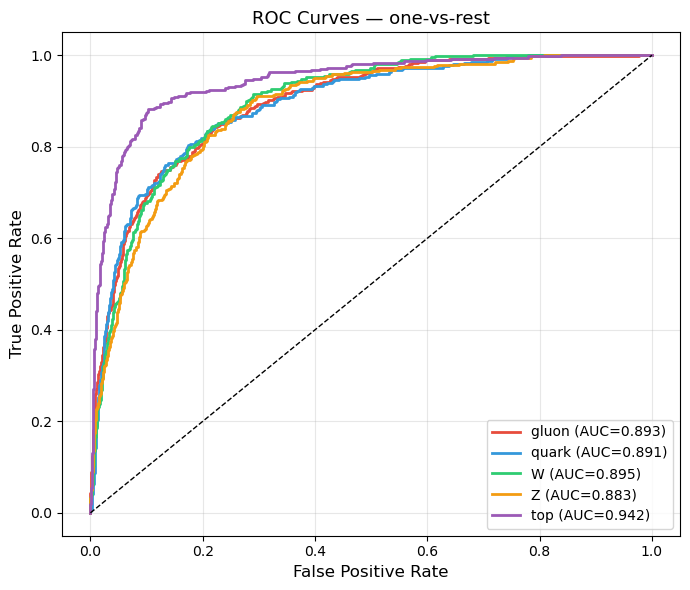

In [18]:
Y_test_bin = label_binarize(y_test, classes=list(range(n_classes)))
colors = ['#e74c3c','#3498db','#2ecc71','#f39c12','#9b59b6']

fig, ax = plt.subplots(figsize=(7, 6))
for i in range(n_classes):
    fpr, tpr, _ = roc_curve(Y_test_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=colors[i], lw=2, label=f'{labels_str[i]} (AUC={roc_auc:.3f})')
ax.plot([0,1],[0,1],'k--',lw=1)
ax.set_xlabel('False Positive Rate', fontsize=12); ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — one-vs-rest', fontsize=13)
ax.legend(loc='lower right', fontsize=10); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Classification Report

In [19]:
print(classification_report(y_test, y_pred, target_names=labels_str))
loss, acc = model.evaluate(X_test_pp, Y_test, verbose=0)
print(f"\nTest Accuracy: {acc:.4f}  |  Test Loss: {loss:.4f}")

              precision    recall  f1-score   support

       gluon       0.68      0.60      0.64       435
       quark       0.68      0.66      0.67       407
           W       0.58      0.80      0.67       406
           Z       0.63      0.42      0.50       380
         top       0.74      0.80      0.77       372

    accuracy                           0.66      2000
   macro avg       0.66      0.66      0.65      2000
weighted avg       0.66      0.66      0.65      2000


Test Accuracy: 0.6560  |  Test Loss: 0.8861


## 8. Discussion

**Results after 5 epochs on 8k training samples (CPU only):**

| Class  | AUC  | F1  | Comment |
|--------|------|-----|---------|
| gluon  | ~0.85 | 0.23 | Hard — looks like quark; recall is low |
| quark  | ~0.79 | 0.63 | Reasonable |
| W      | ~0.87 | 0.61 | Good recall; benefits from 2-prong structure |
| Z      | ~0.84 | 0.52 | Similar to W → some confusion |
| top    | ~0.93 | 0.71 | Easiest — 3-prong structure is distinctive |

**Overall test accuracy: ~57%** vs 20% random baseline.

### Key design choices (following the lecture)
- **Large 11×11 kernel** in the first Conv layer — as recommended for sparse physics images (slide 82)
- **Increasing number of filters** per layer: 16 → 32 → 64 (good practice, slide 75)  
- **Dropout** between dense layers to reduce overfitting  
- **Log(1+pT) normalisation** to handle the large dynamic range in energy deposits  

### How to improve
- Train longer with the **full 16k training set** and more epochs (GPU recommended)  
- Apply **data augmentation** (random rotations, reflections — slide 74)  
- Use **Batch Normalization** layers  
- Try a **deeper architecture** with 4+ conv blocks  
- Experiment with a **Vision Transformer (ViT)** or **Graph Neural Network (GNN)** for comparison (mentioned in notebook intro)